In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05


Note: you may need to restart the kernel to use updated packages.


# GPS Positioning and Relativity

A GPS receiver gets its position from time. Each satellite broadcasts the reading of
its own clock; the receiver measures how long the signal took to arrive and multiplies
by the speed of light to get a range.

Light travels about 30 cm in one nanosecond, so the clocks must agree to within
nanoseconds. At that level relativity is an engineering requirement: a satellite clock
and a ground clock do not tick at the same rate.

## Why We Need Relativity

Two relativistic effects change the rate of a satellite clock, in opposite directions.

**Gravity (general relativity).** A clock higher in a gravity well runs faster. At
20,200 km altitude the satellite clock gains about 46 µs per day on a ground clock.

**Speed (special relativity).** A moving clock runs slower. At 3.9 km/s the satellite
clock loses about 7 µs per day.

The net rate is +38.6 µs/day. Multiplied by the speed of light, that is a range error
growing by 0.13 m every second: 8 m after one minute, 11.6 km after one day.

Real satellites never show this rate: each clock is detuned before launch so that it
ticks slow by exactly this amount. In this notebook the clocks are left undetuned on
purpose, so that we can watch the filter find the rate.

**Eccentricity.** The detuning removes only the average rate. Orbits are slightly
elliptical, so a satellite's altitude and speed change along the orbit, and its clock
runs alternately fast and slow. The offset this leaves is

$$\Delta t_\mathrm{rel}(t)=F\,e\,\sqrt{a}\,\sin E(t),
  \qquad F=-\frac{2\sqrt{\mu}}{c^2}\approx-4.443\times10^{-10}\ \mathrm{s}/\sqrt{\mathrm m},$$

with $a$ and $e$ the semi-major axis and eccentricity of the orbit, $E$ the eccentric
anomaly (the angle that says where the satellite is on its ellipse) and
$\mu=GM_\oplus$. It reaches about 14 m of range for the most eccentric GPS orbits, and it is different
for every satellite. Every real receiver has to correct for it.

The simulation is idealised in three ways: the receiver clock is perfect, the Earth
does not rotate, and there is no atmosphere.

## The Estimator

A real receiver clock is a cheap quartz oscillator that is not synchronised to GPS
time, so the filter must estimate the clock together with the position. That makes
four unknowns, which is why a fix needs at least four satellites.

The measurement to satellite $i$ is called a **pseudorange**: the geometric range plus
everything the clocks add to it,

$$z_i(t)=\lVert \mathbf{s}_i(t)-\mathbf{p}\rVert\;+\;b\;+\;c\,\Delta t_{\mathrm{clock},i}(t)\;+\;\varepsilon_i .$$

| symbol | meaning |
|---|---|
| $\mathbf{p}=[p_x,p_y,p_z]$ | receiver position in an Earth-centred frame [m] |
| $b$ | receiver clock bias, expressed as a range [m] |
| $\dot b$ | receiver clock drift [m/s] |
| $\mathbf{s}_i(t)$ | position of satellite $i$ on its Kepler orbit [m] |
| $\Delta t_{\mathrm{clock},i}$ | relativistic offset of satellite clock $i$: the secular rate times $t$, plus $\Delta t_\mathrm{rel}$ [s] |
| $\varepsilon_i$ | ranging noise, standard deviation 1 m |

The state is $\mathbf{x}=[p_x,p_y,p_z,b,\dot b]$. Its dynamics are linear: the receiver
stands still and the clock bias grows at the rate $\dot b$. The measurement is
nonlinear in the position, so `kalman.apps.gps.GPSModel` is an Extended Kalman Filter
(EKF).

The switch `model.apply_relativistic` decides whether the receiver subtracts
$c\,\Delta t_{\mathrm{clock},i}$ from each pseudorange before filtering. We run the
filter with the switch on and off.

## Step 1 — Set Up the Receiver and Its Sky

We place a receiver at 45° latitude and track the 8 highest satellites. The argument
`pseudorange_uncertainty` is the standard deviation of the ranging noise, in metres.

8 satellites, elevations [deg]: [77.8 51.6 41.5 28.  18.  16.1 13.1  6.8]
pseudoranges: (1800, 8)  mean range ~ 22749 km


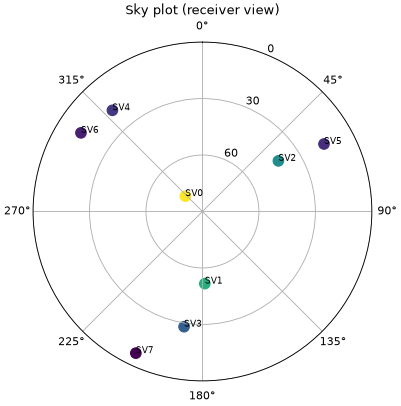

In [2]:
from kalman.apps.gps import GPSModel

# Build a receiver that tracks the 8 highest satellites.
SIGMA_RANGE = 1.0   # ranging noise, standard deviation [m]
gps = GPSModel("rx", receiver_lat=45.0, receiver_lon=10.0, n_sat=8,
               fs=1.0, pseudorange_uncertainty=SIGMA_RANGE)

az, el = gps.azel(0.0)
print(f"{gps.m} satellites, elevations [deg]: {np.round(el, 1)}")

# Simulate 30 minutes of pseudoranges at 1 Hz, relativistic clock offsets included.
chrono.restart()
pseudoranges = gps.simulate(1800.0, seed=0)
chrono.lap("simulated pseudoranges")
print("pseudoranges:", pseudoranges.shape, " mean range ~", round(pseudoranges.mean() / 1e3), "km")

# Sky plot: each point is one satellite, at its azimuth and elevation.
fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.scatter(np.radians(az), 90 - el, s=90, c=el, cmap="viridis")
for i, (a, e) in enumerate(zip(az, el)):
    ax.annotate(f"SV{i}", (np.radians(a), 90 - e), fontsize=8)
ax.set_rmax(90)
ax.set_rticks([0, 30, 60, 90])
ax.set_yticklabels(["90", "60", "30", "0"])
ax.set_title("Sky plot (receiver view)")
plt.show()

## Step 2 — Compare Results With and Without the Relativistic Correction

We filter the same pseudoranges twice, with and without the correction. Both runs
start from the same initial guess, about 50 m from the true position.

position RMSE (after convergence):
  corrected    :   0.48 m
  uncorrected  :   7.23 m


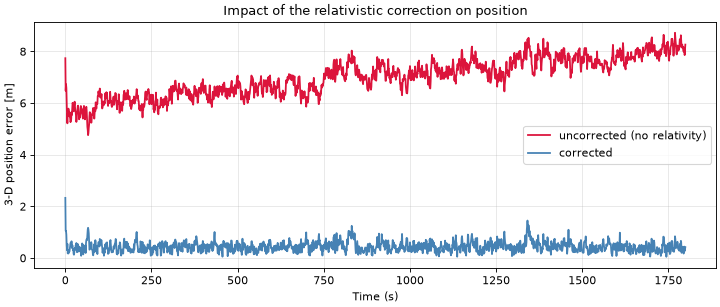

In [3]:
# Start both filters from the same ~50 m offset guess.
guess = np.concatenate([gps.receiver_ecef + [40.0, -30.0, 20.0], [0.0, 0.0]])

gps.apply_relativistic = True
gps.initial_state(guess)
rec_corr = gps.filter(pseudoranges)

gps.apply_relativistic = False
gps.initial_state(guess)
rec_unc = gps.filter(pseudoranges)

t = rec_corr.time
err_corr = gps.position_error(rec_corr)
err_unc = gps.position_error(rec_unc)

# Compare the RMSE after the filter has converged (skip the first 300 s).
rmse_corr = np.sqrt(np.mean(err_corr[300:] ** 2))
rmse_unc = np.sqrt(np.mean(err_unc[300:] ** 2))
print("position RMSE (after convergence):")
print(f"  corrected    : {rmse_corr:6.2f} m")
print(f"  uncorrected  : {rmse_unc:6.2f} m")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, err_unc, color="crimson", lw=1.6, label="uncorrected (no relativity)")
ax.plot(t, err_corr, color="steelblue", lw=1.6, label="corrected")
ax.set_xlabel("Time (s)")
ax.set_ylabel("3-D position error [m]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Impact of the relativistic correction on position")
plt.show()

With the correction the position is good to well under a metre. Without it the
position is off by several metres, and the error does not average out.

The next plot shows the uncorrected run in detail: the East, North and Up errors, and
the estimated clock.

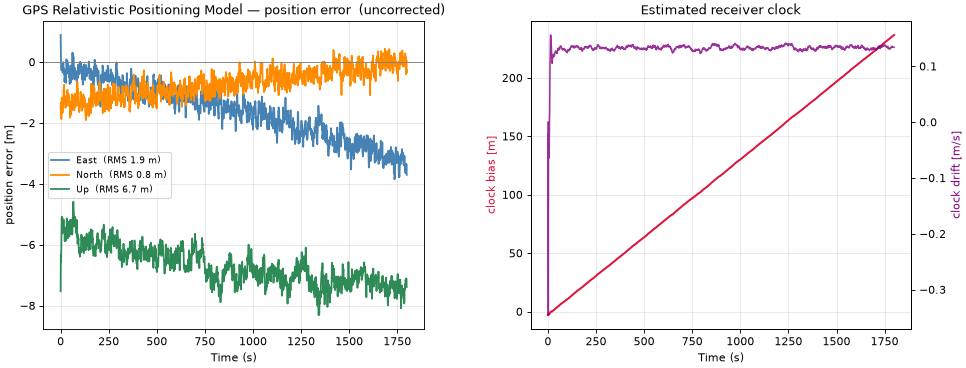

In [4]:
gps.apply_relativistic = False
gps.initial_state(guess)
rec = gps.filter(pseudoranges)
gps.plot(rec, sample=None)
plt.show()


## Step 3 — The Clock Absorbs the Secular Rate

The secular rate adds the same growing offset to every pseudorange. That is exactly
what a drifting receiver clock would do, so the filter cannot tell the two apart: it
puts the rate into its clock drift estimate $\dot b$ and the position is not affected.

The uncorrected $\dot b$ should therefore settle at the relativistic rate, and the
corrected one at zero. The estimate fluctuates a little, so we average it over the
second half of the run.

expected secular rate : 0.1339 m/s  =  +38.6 us/day
uncorrected  b_dot    : 0.1332 m/s  =  +38.4 us/day
corrected    b_dot    : 0.0001 m/s  =  +0.0 us/day


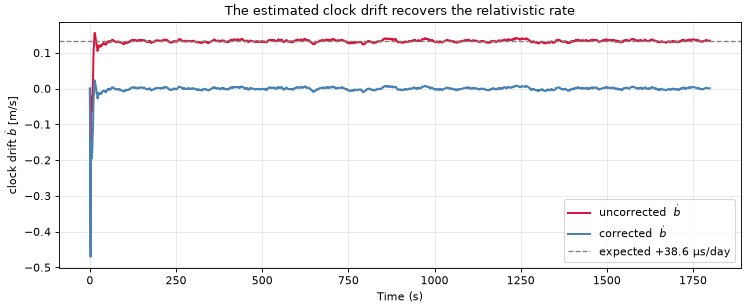

In [5]:
SPEED_OF_LIGHT = 299792458.0

# Expected secular relativistic rate: +38.6 microseconds per day, as a range rate.
secular_rate = SPEED_OF_LIGHT * 38.6e-6 / 86400.0   # m/s

def meters_per_sec_to_us_per_day(v):
    return v / SPEED_OF_LIGHT * 86400.0 * 1e6

half = len(t) // 2
b_dot_unc = rec_unc.xk[half:, 4].mean()
b_dot_corr = rec_corr.xk[half:, 4].mean()

print(f"expected secular rate : {secular_rate:.4f} m/s  =  {meters_per_sec_to_us_per_day(secular_rate):+.1f} us/day")
print(f"uncorrected  b_dot    : {b_dot_unc:.4f} m/s  =  {meters_per_sec_to_us_per_day(b_dot_unc):+.1f} us/day")
print(f"corrected    b_dot    : {b_dot_corr:.4f} m/s  =  {meters_per_sec_to_us_per_day(b_dot_corr):+.1f} us/day")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, rec_unc.xk[:, 4], color="crimson", lw=1.8, label=r"uncorrected  $\dot b$")
ax.plot(t, rec_corr.xk[:, 4], color="steelblue", lw=1.8, label=r"corrected  $\dot b$")
ax.axhline(secular_rate, color="gray", ls="--", lw=1.2, label="expected +38.6 µs/day")
ax.set_xlabel("Time (s)")
ax.set_ylabel(r"clock drift $\dot b$ [m/s]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("The estimated clock drift recovers the relativistic rate")
plt.show()

## Step 4 — The Per-Satellite Eccentricity Correction

The eccentricity term is different for each satellite, so the single clock state
cannot absorb it. The filter can only explain it by moving the position, and this is
what biased the uncorrected run in Step 2.

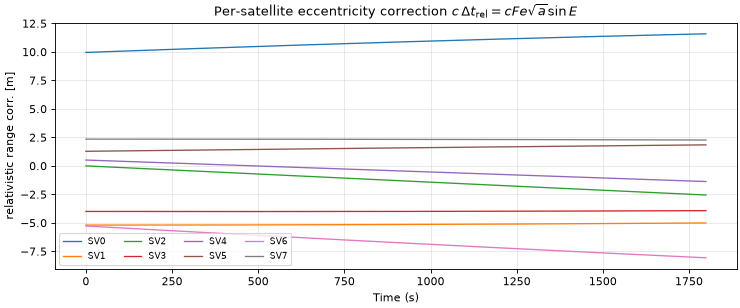

largest correction per satellite: 1.4 to 11.6 m
position error of the uncorrected run: 7.2 m


In [6]:
# Per-satellite eccentricity correction: c * delta_t_rel, converted to metres.
ecc_corr = SPEED_OF_LIGHT * gps.constellation.relativistic_seconds(t)   # (N, M) metres

fig, ax = plt.subplots(figsize=(11, 4))
for i in range(gps.m):
    ax.plot(t, ecc_corr[:, i], lw=1.2, label=f"SV{i}")
ax.set_xlabel("Time (s)")
ax.set_ylabel("relativistic range corr. [m]")
ax.legend(fontsize=8, ncol=4)
ax.grid(alpha=0.3)
ax.set_title(r"Per-satellite eccentricity correction $c\,\Delta t_\mathrm{rel}=cFe\sqrt{a}\sin E$")
plt.show()

correction_size = np.abs(ecc_corr).max(axis=0)
print(f"largest correction per satellite: {correction_size.min():.1f} to {correction_size.max():.1f} m")
print(f"position error of the uncorrected run: {rmse_unc:.1f} m")

## Step 5 — Satellite Visibility and Real-World Accuracy

So far the same 8 satellites stayed in view. Over several hours satellites rise and
set, and buildings or mountains hide the ones low in the sky. Only satellites above a
chosen elevation angle, the **elevation mask**, are usable.

With `elevation_mask` set, `GPSModel` follows all 24 satellites and marks the
pseudorange of a satellite below the mask as `NaN`. The filter skips those and updates
with the satellites that remain.

We run 6 hours under a 25° mask, typical of a street between buildings.

24 satellites tracked;  in view: 2-6 (mean 4.5);  epochs with <4 (no fix): 51  (~26 min of 6 h)


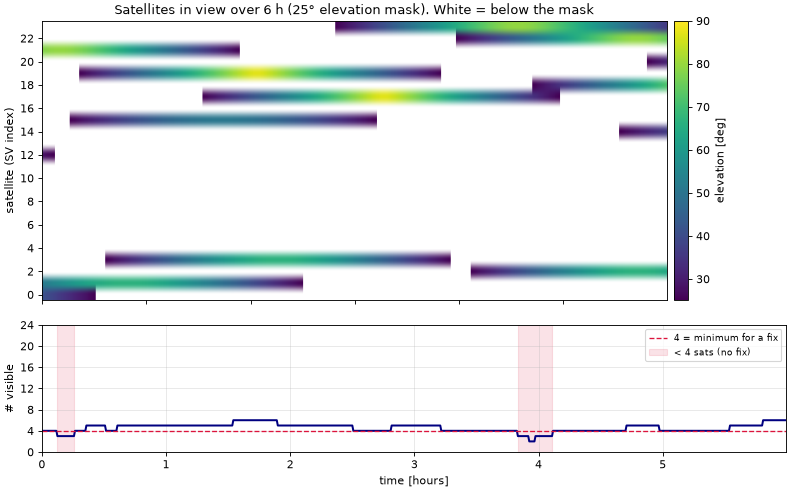

In [7]:
# Track the full constellation through an obstructed urban sky (25 deg elevation mask).
gps2 = GPSModel("rx", receiver_lat=45.0, receiver_lon=10.0, fs=1 / 30.0,
                pseudorange_uncertainty=SIGMA_RANGE, elevation_mask=25.0)

DURATION = 6 * 3600.0                              # 6 hours, in seconds
t = np.arange(int(DURATION * gps2.fs)) / gps2.fs
t_hours = t / 3600.0                               # hours, for the x-axis

az, el = gps2.azel_track(t)      # (N, M) azimuth/elevation of every satellite over time
visible = gps2.visible_mask(t)   # (N, M) True where above the mask
n_visible = gps2.n_visible(t)    # (N,) count of visible satellites at each epoch

no_fix_minutes = (n_visible < 4).sum() / gps2.fs / 60
print(f"{gps2.m} satellites tracked;  in view: {n_visible.min()}-{n_visible.max()} "
      f"(mean {n_visible.mean():.1f});  epochs with <4 (no fix): {int((n_visible < 4).sum())}  "
      f"(~{no_fix_minutes:.0f} min of 6 h)")

fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                             gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.12))

elevation_when_visible = np.where(visible, el, np.nan).T
im = a0.imshow(elevation_when_visible, aspect="auto", origin="lower",
               extent=[t_hours[0], t_hours[-1], -0.5, gps2.m - 0.5],
               cmap="viridis", vmin=25, vmax=90)
a0.set_ylabel("satellite (SV index)")
a0.set_yticks(range(0, gps2.m, 2))
a0.set_title("Satellites in view over 6 h (25° elevation mask). White = below the mask")
fig.colorbar(im, ax=a0, pad=0.01).set_label("elevation [deg]")

a1.plot(t_hours, n_visible, color="navy", lw=1.8)
a1.axhline(4, color="crimson", ls="--", lw=1.2, label="4 = minimum for a fix")
a1.fill_between(t_hours, 0, 1, where=n_visible < 4, transform=a1.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid", label="< 4 sats (no fix)")
a1.set_ylabel("# visible")
a1.set_xlabel("time [hours]")
a1.set_ylim(0, gps2.m)
a1.set_yticks(range(0, gps2.m + 1, 4))
a1.legend(fontsize=8, loc="upper right")
a1.grid(alpha=0.3)
plt.show()

### The Cost to the User: Geometry and Ranging Error

The accuracy of a fix depends on how accurate each range is and on where the
satellites are. Satellites bunched in one part of the sky constrain the position
poorly. The **dilution of precision** (DOP) measures this: to first order

$$\sigma_\text{position} \;\approx\; \text{DOP}\times\sigma_\text{range}.$$

HDOP, VDOP and PDOP are the DOP of the horizontal, the vertical and the full 3-D
position.

We compare two users. A **single-epoch user** computes a fix from one set of
pseudoranges at a time; the horizontal error is $\text{HDOP}\times\sigma_\text{range}$,
and with fewer than 4 satellites there is no fix at all. A **Kalman filter user**
knows that the receiver hardly moves, so it carries the position through the periods
of poor geometry.

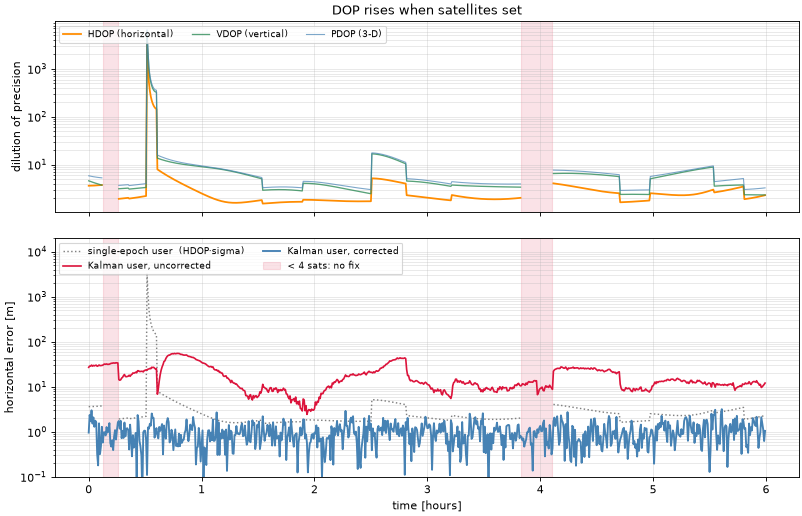

horizontal error
  single-epoch user        : median 2.1 m, worst 3161 m
  Kalman user, corrected   : median 0.94 m, worst 3.2 m
  Kalman user, uncorrected : median 12.8 m, worst 55.4 m


In [8]:
D = gps2.dop(t)                                  # geometry quality of the visible satellites
hdop, vdop, pdop = D["hdop"], D["vdop"], D["pdop"]

# Filter the same sky twice: with and without the relativistic correction.
pseudoranges2 = gps2.simulate(DURATION, seed=0)     # out-of-sight satellites come back as NaN
guess = np.concatenate([gps2.receiver_ecef + [40.0, -30.0, 20.0], [0.0, 0.0]])

gps2.apply_relativistic = True
gps2.initial_state(guess)
rec_corr2 = gps2.filter(pseudoranges2)

gps2.apply_relativistic = False
gps2.initial_state(guess)
rec_unc2 = gps2.filter(pseudoranges2)

horiz_err_corr = np.hypot(*gps2.enu_error(rec_corr2)[:, :2].T)   # horizontal error, corrected
horiz_err_unc = np.hypot(*gps2.enu_error(rec_unc2)[:, :2].T)     # horizontal error, no relativity
snapshot_err = hdop * SIGMA_RANGE                               # single-epoch horizontal error = HDOP * sigma_range
outage = n_visible < 4

fig, (b0, b1) = plt.subplots(2, 1, figsize=(12, 7.4), sharex=True,
                             gridspec_kw=dict(height_ratios=[1, 1.25], hspace=0.12))

b0.semilogy(t_hours, hdop, color="darkorange", lw=1.6, label="HDOP (horizontal)")
b0.semilogy(t_hours, vdop, color="seagreen", lw=1.2, alpha=0.8, label="VDOP (vertical)")
b0.semilogy(t_hours, pdop, color="steelblue", lw=1.0, alpha=0.7, label="PDOP (3-D)")
b0.fill_between(t_hours, 0, 1, where=outage, transform=b0.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid")
b0.set_ylabel("dilution of precision")
b0.grid(alpha=0.3, which="both")
b0.legend(fontsize=8, ncol=3, loc="upper left")
b0.set_title("DOP rises when satellites set")

b1.semilogy(t_hours, np.clip(snapshot_err, 1e-2, None), color="0.5", lw=1.3, ls=":",
            label="single-epoch user  (HDOP·sigma)")
b1.semilogy(t_hours, np.clip(horiz_err_unc, 1e-2, None), color="crimson", lw=1.5,
            label="Kalman user, uncorrected")
b1.semilogy(t_hours, np.clip(horiz_err_corr, 1e-2, None), color="steelblue", lw=1.7,
            label="Kalman user, corrected")
b1.fill_between(t_hours, 0, 1, where=outage, transform=b1.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid", label="< 4 sats: no fix")
b1.set_ylabel("horizontal error [m]")
b1.set_xlabel("time [hours]")
b1.set_ylim(0.1, 2e4)
b1.grid(alpha=0.3, which="both")
b1.legend(fontsize=8, ncol=2, loc="upper left")
plt.show()

print("horizontal error")
print(f"  single-epoch user        : median {np.nanmedian(snapshot_err):.1f} m, worst {np.nanmax(snapshot_err):.0f} m")
print(f"  Kalman user, corrected   : median {np.median(horiz_err_corr[20:]):.2f} m, worst {horiz_err_corr[20:].max():.1f} m")
print(f"  Kalman user, uncorrected : median {np.median(horiz_err_unc[20:]):.1f} m, worst {horiz_err_unc[20:].max():.1f} m")

## Takeaways

- A GPS receiver is an EKF over position, clock bias and clock drift. The clock is
  part of the state because the receiver clock is unknown.
- The net relativistic rate of +38.6 µs/day is the same for every satellite, so it
  ends up in the clock drift estimate and does not move the position. Real satellite
  clocks are detuned before launch to remove it.
- The eccentricity term differs from satellite to satellite, so the clock cannot
  absorb it. Left uncorrected it biases the position by several metres.
- Satellites rise and set. With poor geometry a single-epoch fix can be wrong by
  kilometres, or impossible with fewer than 4 satellites. The Kalman filter stays at
  the metre level through the same periods when the correction is applied, and keeps
  its bias of ten metres or more when it is not.